# Microimages and centroid motion

These are the stellar microimages of **Q2237+0305 image B**, not four galaxy-scale
macroimages. The example keeps the disk at its mean irradiation so the changes
arise from microlensing. Exact source evolution can also retain the disk's own
response delays. We omit the much smaller propagation delays between microimages.

This notebook demonstrates microimage output. The full example needs
a CUDA GPU with Triton and uses 40 million nominal rays and a 1024-square source.
CPU rendering is supported and tested, but this production-sized example is
intended for the GPU. It evaluates 147 epochs at 25-day intervals.

Running all cells generates the simulation, calculates caustic-crossing labels,
checks total flux, and creates the animation from those new outputs. No saved
simulation, external plotting script or pre-existing GIF is loaded.

GIF previews are embedded below. If needed, only their duration is shortened,
keeping the original resolution, cadence, and playback speed. The full GIFs
are generated by this notebook and linked below each animation.


In [1]:
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
import microcaustics as mc
import microcaustics.plotting as plots
from matplotlib.colors import LogNorm
from IPython.display import Image, display
print("Package:", mc.__file__)
assert torch.cuda.is_available(), "This full-resolution example requires CUDA."
output = Path.cwd() / "microimage_notebook_output"
output.mkdir(exist_ok=True)
GIF_DIRECTORY = Path("../assets/animations")
GIF_DIRECTORY.mkdir(parents=True, exist_ok=True)


Package: C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\__init__.py


## Physical setup

The setup and seed match the animation. Six effective wavelengths represent
the LSST bands. These are monochromatic samples, not throughput-integrated bands.
We resolve the field using the original i-band source, then evaluate all bands
on that same physical grid to preserve the stellar realization and aperture.

In [2]:
def make_system():
    torch.set_num_threads(4)
    # Keep intrinsic brightness fixed so all animation changes are lensing.
    source_model = mc.KerrDiskModel(
        black_hole_mass_solar=10**9.08,
        eddington_ratio=0.34,
        spin=0.74,
        inclination_deg=10.0,
        position_angle_deg=0.0,
        wavelengths_angstrom=(7546.0,),
        band_names=("i",),
        lamp_fraction=0.1,
        corona_height_above_isco_rg=20.0,
        source_grid_shape=1024,
        enclosed_flux_fraction=0.999,
        source_margin=1.05,
        compile_solver=False,
        warn_on_compile=False,
    )
    system = mc.MicrolensingSystem(
        lens_redshift=0.0395,
        source_redshift=1.695,
        macro=mc.MacroLens(
            convergence=0.391,
            shear=0.391,
            shear_angle_deg=141.73,
            smooth_matter_fraction=0.0,
        ),
        source=source_model,
        stellar_population=mc.StellarPopulation.salpeter(
            mean_mass_solar=0.3,
            mass_ratio=100.0,
            kinematics=mc.SkyProjectedKinematics(
                ra_deg=340.126125,
                dec_deg=3.358611,
                stellar_dispersion_km_s=170.0,
                peculiar_velocity_dispersion_km_s=235.0,
                include_cmb_dipole=True,
                seed=23,
            ),
        ),
        duration_days=3650.0,
        light_loss=0.01,
        safety_scale=1.5,
        seed=23,
        runtime=mc.RuntimeConfig(
            device="cuda", backend="triton", strict_backend=True, memory_fraction=0.8
        ),
        caustic_grid_shape=1024,
    )
    return system

In [3]:
system = make_system()
realization = system.realize()
bands = dict(zip("ugrizy", (3671., 4827., 6223., 7546., 8691., 9712.), strict=True))
source = realization.source.with_bands(bands)
times = np.arange(0., 3651., 25.)
method = mc.IPMConfig(
    rays=40_000_000, tiled=True, scout_ratio=2, refinement=2,
    virtual_refinement=4, cell_chunk_size=524288,
    compact_sparse_nodes=True, dual_scout_scalar_correction=False,
    far_field_approx=mc.FarFieldApproxConfig(enabled=True),
)
schedule = mc.DynamicConfig(
    temporal_batch_size=25, scout_refresh_frames=10,
    tuning=mc.AutoTuningConfig(enabled=False),
)
print(f"{len(realization.stars)} stars, {len(times)} epochs, {len(bands)} bands")

3630 stars, 147 epochs, 6 bands


## Request microimages while calculating the light curve

The callback alone is enough to request all epochs and bands. Here we choose
only i-band images while retaining all six bands in the light curve. We keep
the small flux and centroid arrays and sparse, cropped native cells for the
animation. We allocate one dense microimage at a time when drawing the GIF.

In [4]:
centroids, image_flux, output_times = [], [], []
display_frames, map_frames = [], []
image_extent = None

def save_map(index, frame):
    map_frames.append(frame.values.cpu().numpy())

def save_frame(index, frame):
    global image_extent
    centroids.append(frame.centroid_uas[0])
    image_flux.append(frame.total_flux_jy[0] + frame.normalization_correction_flux_jy[0])
    output_times.append(frame.time_days)
    cropped = frame.crop((-140, 140, -140, 140))
    image_extent = cropped.grid.bounds_uas
    dy, dx = cropped.grid.pixel_scale_uas
    display_frames.append((cropped.cell_indices.cpu().numpy(),
                           cropped.flux_jy[:, 0].cpu().numpy() * (1e6 / (dx * dy)),
                           cropped.grid.shape))

with torch.inference_mode():
    curve = realization.light_curve(
        times, source=source, method=method, schedule=schedule,
        microimages=mc.MicroimageConfig(bands=["i"]),
        microimage_observer=save_frame,
        map_observer=save_map,
    )
centroid_xy = torch.stack(centroids).cpu().numpy()
microimage_flux = torch.stack(image_flux)
i_index = curve.band_names.index("i")
fractional_error = (microimage_flux / curve.flux[:, i_index] - 1).abs()
torch.testing.assert_close(microimage_flux, curve.flux[:, i_index], rtol=1e-4, atol=1e-12)
np.testing.assert_array_equal(output_times, times)
print(f"Maximum flux mismatch: {float(fractional_error.max()):.3g}")
assert len(map_frames) == len(display_frames) == len(times)

C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\lens\models.py:842: CompilationWarning: Compilation event 1: preparing a new torch.compile specialization for specular stellar-boundary evolution on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  positions, _ = run_tensor_kernel(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\ipm.py:1397: CompilationWarning: Compilation event 2: preparing a new Triton specialization for batched IPM rasterization on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  _warn_new_triton_ipm_specialization(


Maximum flux mismatch: 1.43e-06


The uniform scout correction, when enabled, is reported separately. It has
no known image position and is not included in the centroid. Flux agreement
checks the renderer, but precision astrometry also needs spatial-convergence
tests. Centroids use all original cells, including those outside the display crop.

## Calculate the crossing markers

The image callback does not yet share the caustic-label pass.
We therefore calculate labels separately, using the same stars and epochs.
Markers identify sampled source-center caustic crossings, not photometric peaks.

In [5]:
with torch.inference_mode():
    labeled = realization.simulation.dynamic_labeled_caustics(
        mc.PlaneGrid((8192, 8192), realization.lens_region.field_of_view_uas,
                     center_uas=realization.lens_region.center_uas),
        realization.source_grid.region, times,
        config=mc.CausticConfig(
            far_field_approx=method.far_field_approx, temporal_batch_size=2,
            tuning=mc.AutoTuningConfig(enabled=False),
        ),
    )
crossings = np.array([frame.labels.center_crossing for frame in labeled], dtype=bool)
del labeled
print("Caustic-crossing epochs [days]:", times[crossings])

Caustic-crossing epochs [days]: [ 900. 1325. 1550. 1625. 2625. 2650.]


## Build and save the GIF

Both images use fixed color limits across all epochs. The i-band disk contours
enclose 68%, 95% and 99% of its flux. Microimage intensity is in physical units.
The image crop is only for display. Fluxes and centroids use every retained cell.
The package's GIF writer uses a shared color palette to avoid palette flicker.
Plotting, CPU transfers and encoding take longer than the simulation itself.



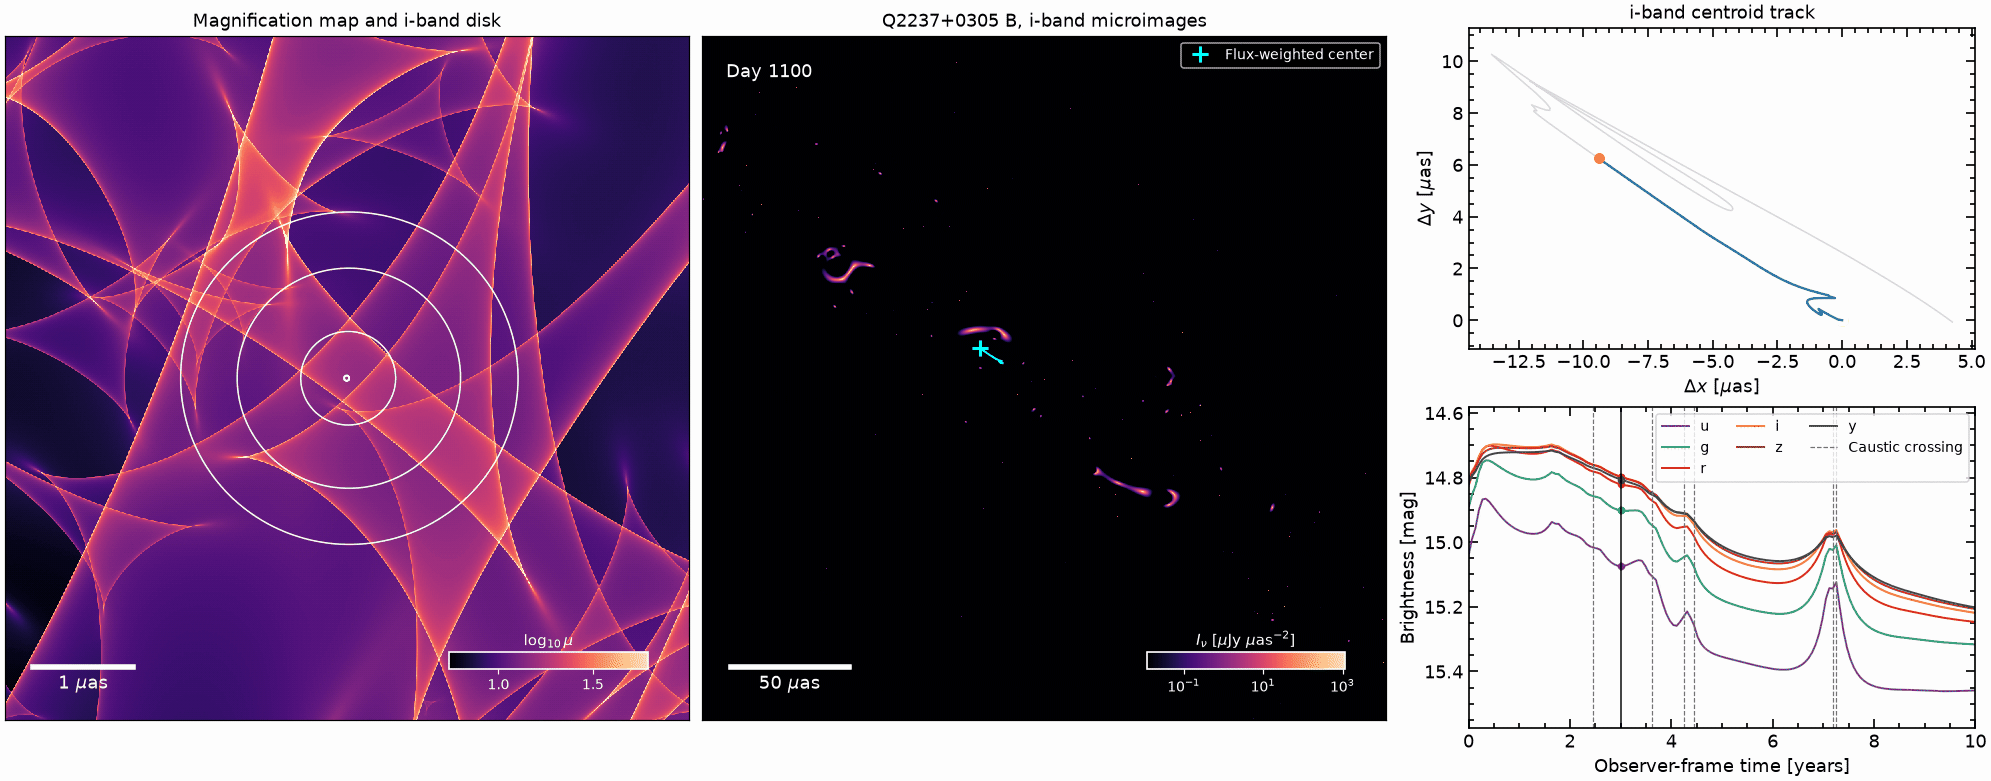

In [6]:
log_maps = np.log10(np.maximum(np.asarray(map_frames), 1e-4))
map_limits = np.percentile(log_maps, [0.1, 99.9])
peak = max(values.max() for _, values, _ in display_frames)

def image_at(index):
    indices, values, shape = display_frames[index]
    image = np.zeros(shape, dtype=np.float32)
    image.reshape(-1)[indices] = values
    return image
years = times / 365.25
magnitudes = curve.magnitude.cpu().numpy()
shift = centroid_xy - centroid_xy[0]
disk = source.brightness([0.], device="cuda")[0, ..., i_index].cpu().numpy()
source_y, source_x = realization.source_grid.axes()

with plt.rc_context(plots.publication_style(font_size=12)):
    fig = plt.figure(figsize=(18.1, 7.1), dpi=110, layout="constrained")
    gs = fig.add_gridspec(2, 3, width_ratios=[1.35, 1.35, 1])
    map_ax, image_ax = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[:, 1])
    track_ax, lc_ax = fig.add_subplot(gs[0, 2]), fig.add_subplot(gs[1, 2])
    map_artist = map_ax.imshow(log_maps[0], origin="lower", cmap="magma",
                              extent=realization.source_grid.bounds_uas,
                              vmin=map_limits[0], vmax=map_limits[1], interpolation="nearest")
    map_ax.contour(source_x.numpy(), source_y.numpy(), disk,
                   levels=plots.enclosed_flux_contour_levels(disk), colors="white", linewidths=1)
    map_ax.set_title("Magnification map and i-band disk")
    image_artist = image_ax.imshow(image_at(0), origin="lower", extent=image_extent,
                                   cmap="magma", norm=LogNorm(peak * 1e-5, peak, clip=True),
                                   interpolation="nearest")
    image_ax.set_title("Q2237+0305 B, i-band microimages")
    for ax, artist, label, bar in (
        (map_ax, map_artist, r"$\log_{10}\mu$", 1),
        (image_ax, image_artist, r"$I_\nu$ [$\mu$Jy $\mu$as$^{-2}$]", 50),
    ):
        plots.hide_image_axes(ax)
        plots.add_scale_bar(ax, bar, label=rf"{bar} $\mu$as", font_size=12, borderpad=1.1)
        color_ax = ax.inset_axes([0.65, 0.075, 0.29, 0.025])
        cb = fig.colorbar(artist, cax=color_ax, orientation="horizontal")
        cb.ax.tick_params(colors="white", labelsize=9, length=3)
        cb.outline.set_edgecolor("white")
        cb.ax.set_title(label, color="white", fontsize=10, pad=4)
    trail, = image_ax.plot([], [], color="cyan", lw=1.3)
    center, = image_ax.plot([], [], "+", color="cyan", ms=11, mew=2, label="Flux-weighted center")
    image_ax.legend(loc="upper right", frameon=True, facecolor="black", labelcolor="white", fontsize=9)
    clock = image_ax.text(0.035, 0.96, "", transform=image_ax.transAxes, color="white", va="top")
    track_ax.plot(shift[:, 0], shift[:, 1], color="0.85", lw=1)
    path, = track_ax.plot([], [], color="C0")
    position, = track_ax.plot([], [], "o", color="C1")
    track_ax.set(title="i-band centroid track", xlabel=r"$\Delta x$ [$\mu$as]",
                 ylabel=r"$\Delta y$ [$\mu$as]")
    track_ax.set_aspect("equal", adjustable="datalim")
    colors = plots.band_colors(curve.band_names)
    points = []
    for j, band in enumerate(curve.band_names):
        lc_ax.plot(years, magnitudes[:, j], color=colors[band], label=band, lw=1.3)
        points.append(lc_ax.plot([], [], "o", color=colors[band], ms=4)[0])
    for j, time in enumerate(times[crossings]):
        lc_ax.axvline(time / 365.25, ls="--", lw=0.8, color="0.45",
                      label="Caustic crossing" if j == 0 else None)
    lc_ax.set(xlabel="Observer-frame time [years]", ylabel="Brightness [mag]", xlim=(0, 10))
    lc_ax.invert_yaxis()
    lc_ax.margins(y=0.15)
    lc_ax.legend(frameon=True, fontsize=9, ncol=3)
    cursor = lc_ax.axvline(0, color="black", lw=1)
    for ax in (track_ax, lc_ax):
        plots.finish_axis(ax)
    fig.canvas.draw()
    fig.set_layout_engine(None)

    def animation_frames():
        for index, time in enumerate(times):
            map_artist.set_data(log_maps[index])
            image_artist.set_data(image_at(index))
            trail.set_data(centroid_xy[:index + 1, 0], centroid_xy[:index + 1, 1])
            center.set_data([centroid_xy[index, 0]], [centroid_xy[index, 1]])
            path.set_data(shift[:index + 1, 0], shift[:index + 1, 1])
            position.set_data([shift[index, 0]], [shift[index, 1]])
            cursor.set_xdata([years[index]] * 2)
            clock.set_text(f"Day {time:.0f}")
            for j, point in enumerate(points):
                point.set_data([years[index]], [magnitudes[index, j]])
            fig.canvas.draw()
            # Capture before savefig, whose tight bounding box changes the renderer size.
            rgb = np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()
            if index in (0, 63, len(times) - 1):
                fig.savefig(output / f"preview_{index:03d}.png", dpi=110)
            yield rgb

    gif_path = plots.save_fixed_palette_gif(
        animation_frames(), GIF_DIRECTORY / "q2237_b_microimages.gif", fps=12.5, colors=256,
    )
    plt.close(fig)
from PIL import Image as PILImage
with PILImage.open(gif_path) as gif:
    assert gif.n_frames == len(times)
    for index in range(gif.n_frames):
        gif.seek(index)
        gif.load()
print(f"Generated and checked {len(times)} frames: {gif_path}")
display(plots.gif_preview(gif_path, start_frame=44, stop_frame=74))

[View the full GIF](../assets/animations/q2237_b_microimages.gif)

## Output selection and current limits

To save only a few epochs, use `MicroimageConfig(times_days=[0, 100, 200], bands=["i"])`.
The times must occur in the light curve's map cadence. Omitting `times_days`
uses all evaluated epochs, and omitting `bands` uses every curve band.
Omitting both the callback and configuration leaves an ordinary light curve.

This first interface requires exact source evolution on the native map grid
and a fixed source center. Separate map/photometry cadences, response
approximations, bandpass integration and integrated label output raise errors.
This notebook calculates the caustic labels separately, rather than loading
crossing times from an earlier run. The callback does not infer crossings
from flux peaks. The displayed microimage
panel is cropped to the central 280 microarcseconds, while fluxes and centroids
use all retained cells.